# 07 — Case study: forecast temperature profiles at representative mPING reports

Skew-T style temperature profiles (height AGL, 0–5 km) at one representative mPING report per observed class, valid **1800 UTC 3 February 2022**. Replaces the original Discussion figure (`mping_ptype_profile_1.pdf`).

**What is shown in each panel**
- The forecast temperature profile from each of the **6 forecast models** (Aurora, GraphCast, WXFormer, FuXi, Pangu-Weather, GFS) at the nearest native grid point.
- **All 12 systems** in the legend: for each model, the ptype diagnosed from its profile by EDNN and by Bourgouin (native for GFS). The two systems of a model share one line, since both algorithms use the identical profile. Because both algorithms see the identical profile, the figure separates two error sources:
  - **profile error:** the forecast model gets the thermal structure wrong (differences between the lines);
  - **diagnostic error:** the algorithm reads the same profile differently (differences between the two labels on one line).
- The **RAP profile** at the report location (thick grey), from the RAP fields interpolated to each mPING report in the QC'd parquet. This is the same reference RAP used for the QC and the temperature analysis.
- The solid black skewed line is the 0 °C isotherm.

**Selecting the reports.** Section 5 lists every report at the case time with the class each system diagnoses. By default (`SELECT = "auto"`) the notebook picks, for each class, the unanimous (100 %) report closest to the median location of that class. Set `REPORTS` to choose specific reports instead.

**Outputs** (in `OUT` and `FIG`)

| File | Contents |
|---|---|
| `case_study_profiles_<time>_day<d>.pdf` | 2 × 2 skew-T figure |
| `case_study_profile_candidates_<time>_day<d>.csv` | All case-time reports with every system's diagnosis |
| `case_study_profile_diagnostics_<time>_day<d>.csv` | Surface temperature, warm-layer maximum and cold-layer depth for each selected profile |

> Run with **Kernel → Restart & Run All**. Copy `MODEL_DIRS`, `FILE_GLOBS` and `PTYPE_VAR` from your notebook 05.

## 1. Imports

In [1]:
from pathlib import Path
import glob, re
import numpy as np
import pandas as pd
import xarray as xr
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
import metpy.plots   # registers the "skewx" projection

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

## 2. Configuration

**Copy from notebook 05:** `MODEL_DIRS`, `FILE_GLOBS`, `PTYPE_VAR`.

- `T_VAR`: forecast temperature-on-height variable (`T_HEIGHT` in the EDNN output files).
- `HEIGHTS_FALLBACK`: heights (m AGL) used only if the files carry no height coordinate.
- `RAP_T_PATTERN`: regex for the RAP temperature columns in the parquet (`TEMP_C_<height>_m`).
- `SELECT` / `REPORTS`: how the representative report for each class is chosen (Section 5).

In [2]:
# ============================================================
# PATHS, CASE, OBSERVED-CLASS RULE (same as notebooks 01–06)
# ============================================================
OBS_RULE = "modal"
_RULE_SUFFIX = "" if OBS_RULE == "consensus" else f"_{OBS_RULE}"
MPING_PATH = "/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/mPING_hourafter_interpolated_QC3.parquet"
AI_BASE = Path("/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE")
OUT = AI_BASE / f"verification_multimodel{_RULE_SUFFIX}"
FIG = Path("/glade/work/sakor/AI_NWP") / f"figures{_RULE_SUFFIX}"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

VALID = pd.Timestamp("2022-02-03 18:00")
FORECAST_DAY = 1
LAT_MIN, LAT_MAX, LON_MIN, LON_MAX = 24.0, 50.0, -125.0, -66.0
PTYPE_COLS = {"sn_percent": "Snow", "ra_percent": "Rain",
              "pl_percent": "Ice Pellet", "fzra_percent": "Freezing Rain"}
TIE_PRIORITY = ["fzra_percent", "pl_percent", "sn_percent", "ra_percent"]

# ============================================================
# FORECAST FILES AND VARIABLES  (copy from notebook 05)
# ============================================================
MODELS = ["Aurora", "GraphCast", "WXFormer", "FuXi", "Pangu-Weather", "GFS"]
MODEL_DIRS = {
    "Aurora": AI_BASE / "au_ptype",
    "GraphCast": AI_BASE / "gc_ptype",
    "Pangu-Weather": AI_BASE / "pw_ptype",
    "WXFormer": AI_BASE / "wx_ptype",
    "FuXi": AI_BASE / "fuxi_ptype",
    "GFS": Path("/glade/derecho/scratch/sakor/gfs/processed"),
}
FILE_GLOBS = [                          # tried in order; the first unique match wins
    "{init:%Y-%m-%dT%H}Z/*_{lead:03d}.nc",      # e.g. 2022-02-03T00Z/aurora_2022-02-03T00Z_018.nc
    "{init:%Y-%m-%dT%H}Z/*_{lead}.nc",
    "{init:%Y%m%d%H}/*_{lead}.nc",
    "{init:%Y%m%d%H}/*_{lead:03d}.nc",
    "*{init:%Y%m%d%H}*_{lead}.nc",
    "*{init:%Y%m%d%H}*_{lead:03d}.nc",
]
PTYPE_VAR = {"EDNN": "ML_ptype", "Bourgouin": "BOURG_ptype", "Native": None}   # None = auto-detect
NATIVE_PATTERNS = [r"^ptype_gfs$", r"gfs.*ptype|ptype.*gfs", r"native", r"^ptype$"]
# T_VAR = "DPT_HEIGHT"
T_VAR = "T_HEIGHT"
HEIGHTS_FALLBACK = np.arange(0, 5001, 250)
MAX_POINT_KM = 30.0

# ============================================================
# RAP REFERENCE PROFILE (QC'd parquet)
# ============================================================
RAP_T_PATTERN = re.compile(r"^TEMP_C_(\d+)_m$")

# ============================================================
# REPORT SELECTION
# ============================================================
PANEL_CLASSES = ["Rain", "Snow", "Freezing Rain", "Ice Pellet"]
SELECT = "auto"            # "auto" | "manual"
REPORTS = {}               # manual: {"Ice Pellet": (lat, lon), ...}; nearest report of that class is used
MIN_CONSENSUS = 100.0      # auto: prefer unanimous reports (falls back to the highest available)

# ============================================================
# STYLE
# ============================================================
MODEL_COLORS = {"Aurora": "#0072B2", "GraphCast": "#E69F00", "WXFormer": "#009E73",
                "FuXi": "#CC79A7", "Pangu-Weather": "#D55E00", "GFS": "#000000"}
MODEL_LS = {"Aurora": "-", "GraphCast": "-.", "WXFormer": "--",
            "FuXi": "-", "Pangu-Weather": "-", "GFS": ":"}
RAP_STYLE = dict(color="0.55", lw=3.2, alpha=0.8, zorder=1)
ABBR = {0: "rain", 1: "snow", 2: "icep", 3: "frzr", -1: "none"}
CLASS_NAMES = {0: "Rain", 1: "Snow", 2: "Ice Pellet", 3: "Freezing Rain"}
X_LIM, Y_LIM, SKEW = (-15, 30), (-100, 5100), 30

plt.rcParams.update({"font.family": "sans-serif", "font.size": 8,
                     "pdf.fonttype": 42, "ps.fonttype": 42})

## 3. Helpers

In [3]:
def init_and_lead(valid, day):
    init = (valid - pd.Timedelta(hours=1)).floor("D") - pd.Timedelta(days=day - 1)
    lead = int((valid - init) / pd.Timedelta(hours=1))
    assert 24 * (day - 1) + 6 <= lead <= 24 * day, (init, lead)
    return init, lead

def forecast_file(model, init, lead):
    tried = []
    for pat in FILE_GLOBS:
        p = str(MODEL_DIRS[model] / pat.format(init=init, lead=lead))
        hits = sorted(glob.glob(p))
        tried.append(p)
        if len(hits) == 1:
            return Path(hits[0])
        if len(hits) > 1:
            raise RuntimeError(f"{model}: {len(hits)} files match {p}")
    raise FileNotFoundError(f"{model}: no file for init {init}, lead {lead}. Tried:\n  " + "\n  ".join(tried))

def pick_var(ds, method):
    if PTYPE_VAR.get(method):
        return PTYPE_VAR[method]
    names = list(ds.data_vars)
    for pat in NATIVE_PATTERNS:
        hits = [n for n in names if re.search(pat, n, re.I)]
        if len(hits) == 1:
            return hits[0]
    raise KeyError(f"cannot identify the {method} ptype variable among {names}; set PTYPE_VAR['{method}'].")

def _latlon_names(ds):
    lat = next(n for n in ("latitude", "lat", "XLAT", "gridlat_0") if n in ds.variables)
    lon = next(n for n in ("longitude", "lon", "XLONG", "gridlon_0") if n in ds.variables)
    return lat, lon

def _xyz(lat, lon):
    la, lo = np.radians(lat), np.radians(lon)
    return np.c_[np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)]

def _chord_to_km(d):
    return 2 * 6371.0 * np.arcsin(np.clip(d / 2, 0, 1))

class PointSampler:
    # Nearest native grid point for a set of (lat, lon); works for 1-D or 2-D lat/lon.
    def __init__(self, ds, lat_p, lon_p):
        self.lat_n, self.lon_n = _latlon_names(ds)
        lat, lon = ds[self.lat_n].values, ds[self.lon_n].values
        self.one_d = lat.ndim == 1 and lon.ndim == 1
        lon2, lat2 = np.meshgrid(lon, lat) if self.one_d else (lon, lat)
        lon2 = ((lon2 + 180.0) % 360.0) - 180.0
        d, i = cKDTree(_xyz(lat2.ravel(), lon2.ravel())).query(_xyz(lat_p, lon_p))
        self.dist_km = _chord_to_km(d)
        self.iy, self.ix = np.unravel_index(i, lat2.shape)

    def _isel(self, da):
        if self.one_d:
            return da.isel({self.lat_n: xr.DataArray(self.iy, dims="pt"),
                            self.lon_n: xr.DataArray(self.ix, dims="pt")})
        ydim, xdim = da[self.lat_n].dims if self.lat_n in da.coords else da.dims[-2:]
        return da.isel({ydim: xr.DataArray(self.iy, dims="pt"),
                        xdim: xr.DataArray(self.ix, dims="pt")})

    def values(self, da):
        v = self._isel(da.squeeze(drop=True))
        other = [d for d in v.dims if d != "pt"]
        return v.transpose("pt", *other).values.astype(float), other

def heights_of(ds, var):
    da = ds[var].squeeze(drop=True)
    lat_n, lon_n = _latlon_names(ds)
    hdim = [d for d in da.dims if d not in (lat_n, lon_n) and d not in ds[lat_n].dims]
    if len(hdim) != 1:
        raise ValueError(f"{var}: cannot identify the height dimension among {da.dims}")
    h = ds[hdim[0]].values if hdim[0] in ds.coords else HEIGHTS_FALLBACK
    return np.asarray(h, float)

def to_celsius(t):
    return t - 273.15 if np.nanmedian(t) > 200 else t

## 4. mPING reports and RAP profiles at the case time

The observed class follows the same modal rule as notebooks 01–06. The RAP temperature profile at each report comes from the `TEMP_C_<height>_m` columns of the QC'd parquet.

In [4]:
schema = pq.read_schema(MPING_PATH).names
rap_cols = sorted([c for c in schema if RAP_T_PATTERN.match(c)],
                  key=lambda c: int(RAP_T_PATTERN.match(c).group(1)))
RAP_H = np.array([int(RAP_T_PATTERN.match(c).group(1)) for c in rap_cols], float)
print(f"RAP temperature columns: {len(rap_cols)} levels, {RAP_H.min():.0f}–{RAP_H.max():.0f} m AGL")

obs = pd.read_parquet(MPING_PATH, columns=["datetime", "lat", "lon"] + TIE_PRIORITY + rap_cols)
obs["datetime"] = pd.to_datetime(obs["datetime"])
obs = obs[(obs.datetime == VALID) & obs.lat.between(LAT_MIN, LAT_MAX) & obs.lon.between(LON_MIN, LON_MAX)]
raw = obs[TIE_PRIORITY].astype(float).fillna(0.0)
if raw.to_numpy().max() <= 1.0:
    raw = raw * 100.0
obs = obs.assign(obs_consensus=raw.max(axis=1), obs_class=raw.round(6).idxmax(axis=1).map(PTYPE_COLS))
obs = obs[obs.obs_consensus > 0].reset_index(drop=True)
RAP_T = to_celsius(obs[rap_cols].to_numpy(float))
print(f"Reports at {VALID:%Y-%m-%d %H}Z: {len(obs)}")
display(obs.obs_class.value_counts().reindex(PANEL_CLASSES, fill_value=0).to_frame("reports"))

RAP temperature columns: 67 levels, 0–16500 m AGL
Reports at 2022-02-03 18Z: 586


,reports
obs_class,
Rain,146
Snow,218
Freezing Rain,36
Ice Pellet,186


## 5. Forecast profiles and diagnoses at every report

Each model file is opened once. For every report, the notebook takes the nearest native grid point and reads the temperature profile and both ptype diagnoses. The **candidate table** lists every report with all 12 diagnoses, so you can see which reports illustrate the points you want to make and choose them in `REPORTS`.

In [5]:
INIT, LEAD = init_and_lead(VALID, FORECAST_DAY)
TAG = f"{VALID:%Y%m%d_%H}z_day{FORECAST_DAY}"
print(f"Day {FORECAST_DAY}: init {INIT:%Y-%m-%d %H}Z, lead {LEAD} h\n")

lat_p, lon_p = obs.lat.to_numpy(), obs.lon.to_numpy()
prof, diag, heights = {}, {}, {}
for model in MODELS:
    f = forecast_file(model, INIT, LEAD)
    methods = ["EDNN", "Native"] if model == "GFS" else ["EDNN", "Bourgouin"]
    with xr.open_dataset(f, decode_timedelta=False) as ds:
        s = PointSampler(ds, lat_p, lon_p)
        far = s.dist_km > MAX_POINT_KM
        t, _ = s.values(ds[T_VAR])
        heights[model] = heights_of(ds, T_VAR)
        prof[model] = np.where(far[:, None], np.nan, to_celsius(t))
        for m in methods:
            var = pick_var(ds, m)
            v, _ = s.values(ds[var])
            diag[(model, m)] = np.where(far, np.nan, v.ravel())
        print(f"{model:14s} {f.name}: T '{T_VAR}' {heights[model].size} levels "
              f"({heights[model].min():.0f}–{heights[model].max():.0f} m), "
              f"ptype {[pick_var(ds, m) for m in methods]}, max dist {s.dist_km.max():.1f} km")

cand = obs[["lat", "lon", "obs_class", "obs_consensus"]].copy()
for (model, m), v in diag.items():
    cand[f"{model}|{m}"] = pd.Series(v).map(ABBR)
cand.to_csv(OUT / f"case_study_profile_candidates_{TAG}.csv", index_label="report")
print("\nCandidate reports (first rows of each class):")
for cls in PANEL_CLASSES:
    display(cand[cand.obs_class == cls].head(8))

Day 1: init 2022-02-03 00Z, lead 18 h

Aurora         aurora_2022-02-03T00Z_018.nc: T 'T_HEIGHT' 21 levels (0–5000 m), ptype ['ML_ptype', 'BOURG_ptype'], max dist 17.6 km
GraphCast      graphcast_2022-02-03T00Z_018.nc: T 'T_HEIGHT' 21 levels (0–5000 m), ptype ['ML_ptype', 'BOURG_ptype'], max dist 17.6 km
WXFormer       wxformer_2022-02-03T00Z_018.nc: T 'T_HEIGHT' 21 levels (0–5000 m), ptype ['ML_ptype', 'BOURG_ptype'], max dist 19.5 km
FuXi           fuxi_2022-02-03T00Z_018.nc: T 'T_HEIGHT' 21 levels (0–5000 m), ptype ['ML_ptype', 'BOURG_ptype'], max dist 19.5 km
Pangu-Weather  pangu_2022-02-03T00Z_018.nc: T 'T_HEIGHT' 21 levels (0–5000 m), ptype ['ML_ptype', 'BOURG_ptype'], max dist 17.6 km
GFS            gfs_2022-02-03T00Z_018.nc: T 'T_HEIGHT' 21 levels (0–5000 m), ptype ['ML_ptype', 'GFS_ptype'], max dist 17.6 km

Candidate reports (first rows of each class):


,lat,lon,obs_class,obs_consensus,Aurora|EDNN,Aurora|Bourgouin,GraphCast|EDNN,GraphCast|Bourgouin,WXFormer|EDNN,WXFormer|Bourgouin,FuXi|EDNN,FuXi|Bourgouin,Pangu-Weather|EDNN,Pangu-Weather|Bourgouin,GFS|EDNN,GFS|Native
0,38.965794,-82.685120,Rain,100.0,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,frzr,frzr
1,38.259773,-84.583466,Rain,100.0,frzr,frzr,rain,rain,rain,frzr,rain,frzr,rain,rain,frzr,frzr
3,38.023483,-84.606567,Rain,100.0,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,frzr
4,37.905247,-84.618073,Rain,100.0,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,frzr
5,37.795956,-84.779297,Rain,100.0,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain
6,37.677593,-84.790588,Rain,100.0,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain
7,40.918938,-77.780945,Rain,100.0,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain
8,39.251476,-81.733948,Rain,100.0,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,frzr


,lat,lon,obs_class,obs_consensus,Aurora|EDNN,Aurora|Bourgouin,GraphCast|EDNN,GraphCast|Bourgouin,WXFormer|EDNN,WXFormer|Bourgouin,FuXi|EDNN,FuXi|Bourgouin,Pangu-Weather|EDNN,Pangu-Weather|Bourgouin,GFS|EDNN,GFS|Native
150,41.567570,-82.839600,Snow,100.0,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow
152,40.169868,-83.004700,Snow,100.0,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow
153,41.355946,-83.176941,Snow,100.0,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow
154,41.142948,-81.800201,Snow,100.0,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow
155,41.502560,-81.909698,Snow,100.0,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow
156,41.386524,-81.924683,Snow,100.0,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow
157,41.037971,-81.969421,Snow,100.0,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow
158,40.805229,-81.999084,Snow,100.0,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow


,lat,lon,obs_class,obs_consensus,Aurora|EDNN,Aurora|Bourgouin,GraphCast|EDNN,GraphCast|Bourgouin,WXFormer|EDNN,WXFormer|Bourgouin,FuXi|EDNN,FuXi|Bourgouin,Pangu-Weather|EDNN,Pangu-Weather|Bourgouin,GFS|EDNN,GFS|Native
2,38.141659,-84.595032,Freezing Rain,50.0,frzr,frzr,rain,rain,rain,rain,rain,rain,rain,rain,frzr,frzr
74,31.761612,-89.166962,Freezing Rain,50.0,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain
77,38.141659,-84.595032,Freezing Rain,50.0,frzr,frzr,rain,rain,rain,rain,rain,rain,rain,rain,frzr,frzr
149,31.761612,-89.166962,Freezing Rain,50.0,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain
167,40.014553,-84.253967,Freezing Rain,50.0,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow
195,41.267578,-80.379395,Freezing Rain,50.0,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow
218,30.171011,-95.702454,Freezing Rain,50.0,rain,rain,rain,frzr,rain,frzr,rain,frzr,icep,frzr,icep,frzr
294,40.014553,-84.253967,Freezing Rain,50.0,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow


,lat,lon,obs_class,obs_consensus,Aurora|EDNN,Aurora|Bourgouin,GraphCast|EDNN,GraphCast|Bourgouin,WXFormer|EDNN,WXFormer|Bourgouin,FuXi|EDNN,FuXi|Bourgouin,Pangu-Weather|EDNN,Pangu-Weather|Bourgouin,GFS|EDNN,GFS|Native
151,39.935909,-83.031769,Ice Pellet,50.000000,snow,snow,snow,icep,snow,snow,snow,snow,snow,snow,snow,icep
168,39.662964,-84.290283,Ice Pellet,50.000000,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow
189,40.887421,-81.522400,Ice Pellet,50.000000,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow
190,40.875748,-81.368500,Ice Pellet,50.000000,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow
191,41.060234,-80.720795,Ice Pellet,50.000000,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,icep
194,41.383553,-80.362671,Ice Pellet,42.857143,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow
200,33.068024,-96.583618,Ice Pellet,50.000000,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow
202,33.187099,-96.729340,Ice Pellet,50.000000,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,none


## 6. Select one report per class

- `SELECT = "auto"`: among reports of the class with consensus ≥ `MIN_CONSENSUS` (or the highest consensus available), the report closest to the median latitude/longitude of that class. Deterministic and not chosen by outcome.
- `SELECT = "manual"`: for each class in `REPORTS`, the report of that class nearest to the given (lat, lon). Classes not listed fall back to auto.

In [6]:
def pick_report(cls):
    sub = cand[cand.obs_class == cls]
    if sub.empty:
        return None
    if SELECT == "manual" and cls in REPORTS:
        la, lo = REPORTS[cls]
        return int(((sub.lat - la) ** 2 + (sub.lon - lo) ** 2).idxmin())
    top = sub[sub.obs_consensus >= min(MIN_CONSENSUS, sub.obs_consensus.max())]
    la, lo = sub.lat.median(), sub.lon.median()
    return int(((top.lat - la) ** 2 + ((top.lon - lo) * np.cos(np.radians(la))) ** 2).idxmin())

chosen = {cls: pick_report(cls) for cls in PANEL_CLASSES}
display(cand.loc[[r for r in chosen.values() if r is not None]])

,lat,lon,obs_class,obs_consensus,Aurora|EDNN,Aurora|Bourgouin,GraphCast|EDNN,GraphCast|Bourgouin,WXFormer|EDNN,WXFormer|Bourgouin,FuXi|EDNN,FuXi|Bourgouin,Pangu-Weather|EDNN,Pangu-Weather|Bourgouin,GFS|EDNN,GFS|Native
44,39.702271,-79.985260,Rain,100.0,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain,rain
267,38.606342,-89.551880,Snow,100.0,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow,snow
562,38.876171,-84.979034,Freezing Rain,100.0,icep,icep,icep,icep,snow,icep,icep,frzr,icep,icep,icep,icep
475,38.682388,-85.756470,Ice Pellet,100.0,icep,icep,snow,icep,snow,icep,icep,frzr,icep,icep,icep,icep


## 7. Profile diagnostics

For each selected report and profile (6 models + RAP):
- `T_sfc`: temperature at the lowest level (°C);
- `warm_max` / `warm_max_z`: maximum temperature in the 0–5 km column and its height (the peak of the melting layer when it lies above a colder surface layer);
- `cold_depth`: depth of the near-surface subfreezing layer (m; 0 if the surface is above freezing).

These quantify what the figure shows, e.g. whether a misclassified freezing rain profile has an above-freezing surface.

In [7]:
def describe(h, t):
    ok = np.isfinite(t)
    h, t = h[ok], t[ok]
    if t.size == 0:
        return dict(T_sfc=np.nan, warm_max=np.nan, warm_max_z=np.nan, cold_depth=np.nan)
    k = int(np.argmax(t))
    cold = 0.0
    if t[0] < 0:
        above = np.where(t >= 0)[0]
        cold = h[above[0]] - h[0] if above.size else h[-1] - h[0]
    return dict(T_sfc=t[0], warm_max=t[k], warm_max_z=h[k], cold_depth=cold)

rows = []
for cls, r in chosen.items():
    if r is None:
        continue
    rows.append({"obs_class": cls, "profile": "RAP", **describe(RAP_H, RAP_T[r])})
    for model in MODELS:
        meth = "Native" if model == "GFS" else "Bourgouin"
        rows.append({"obs_class": cls, "profile": model,
                     "EDNN": ABBR.get(diag[(model, 'EDNN')][r], "nan"),
                     meth: ABBR.get(diag[(model, meth)][r], "nan"),
                     **describe(heights[model], prof[model][r])})
pdiag = pd.DataFrame(rows).set_index(["obs_class", "profile"])
pdiag.to_csv(OUT / f"case_study_profile_diagnostics_{TAG}.csv")
display(pdiag.round(2))

T_sfc  warm_max  warm_max_z  cold_depth  EDNN Bourgouin Native
obs_class     profile                                                                      
Rain          RAP             3.29      6.51       750.0         0.0   NaN       NaN    NaN
              Aurora          7.57      7.57         0.0         0.0  rain      rain    NaN
              GraphCast       7.87      7.87         0.0         0.0  rain      rain    NaN
              WXFormer        6.41      6.41         0.0         0.0  rain      rain    NaN
              FuXi            7.40      7.69       250.0         0.0  rain      rain    NaN
              Pangu-Weather   8.30      8.30         0.0         0.0  rain      rain    NaN
              GFS             1.32      5.64       750.0         0.0  rain       NaN   rain
Snow          RAP            -6.27     -4.87      2500.0     16500.0   NaN       NaN    NaN
              Aurora         -6.00     -4.58      2750.0      5000.0  snow      snow    NaN
              GraphCast      -4.71     -4.71         0.0      5000.0  snow      snow    NaN
              WXFormer       -4.91     -4.07      2000.0      5000.0  snow      snow    NaN
              FuXi           -5.28     -4.61      2000.0      5000.0  snow      snow    NaN
              Pangu-Weather  -5.78     -5.14      2750.0      5000.0  snow      snow    NaN
              GFS            -5.27     -4.62      2250.0      5000.0  snow       NaN   snow
Freezing Rain RAP            -1.58      1.98      1250.0      1000.0   NaN       NaN    NaN
              Aurora         -3.43      1.64      1250.0      1250.0  icep      icep    NaN
              GraphCast      -2.53      1.76      1250.0      1000.0  icep      icep    NaN
              WXFormer       -2.57      0.49      2000.0      1500.0  snow      icep    NaN
              FuXi           -2.40      1.04      2000.0      1000.0  icep      frzr    NaN
              Pangu-Weather  -2.51      1.58      1250.0      1000.0  icep      icep    NaN
              GFS            -5.06      1.35      1250.0      1000.0  icep       NaN   icep
Ice Pellet    RAP            -1.96      1.66      1250.0      1250.0   NaN       NaN    NaN
              Aurora         -3.41      1.50      1250.0      1250.0  icep      icep    NaN
              GraphCast      -2.45      1.58      1250.0      1250.0  snow      icep    NaN
              WXFormer       -2.45      0.62      2000.0      1500.0  snow      icep    NaN
              FuXi           -2.42      1.06      2000.0      1250.0  icep      frzr    NaN
              Pangu-Weather  -2.78      1.55      1250.0      1250.0  icep      icep    NaN
              GFS            -4.59      1.07      1250.0      1250.0  icep       NaN   icep

## 8. Figure

Based on the original `skewCompositeFigAx` routine (skew-x projection, height AGL on the y-axis, 0 °C isotherm as the solid skewed line), arranged 2 × 2.

The legend under each panel lists **all 12 systems**: EDNN in the left column, Bourgouin (native for GFS) in the right column. The two systems of a model share one line, because both algorithms diagnose ptype from the **same** forecast profile. Each diagnosis is coloured by class (rain green, snow blue, ice pellets pink, freezing rain orange), so correct and incorrect diagnoses stand out against the panel's observed class.

In [8]:
def skew_axes_grid(nrows=2, ncols=2, figsize=(10, 9.2)):
    fig = plt.figure(figsize=figsize)
    axs = []
    for k in range(nrows * ncols):
        ax = fig.add_subplot(nrows, ncols, k + 1, projection="skewx", rotation=SKEW)
        ax.grid(which="both")
        ax.set_xticks(np.arange(-100, 100, 5))
        ax.grid(which="major", alpha=0.5)
        ax.axvline(x=0, ymin=0, ymax=1, c="0", lw=1.2)
        ax.set_ylim(*Y_LIM)
        ax.set_xlim(*X_LIM)
        if k % ncols == 0:
            ax.set_ylabel("Height AGL (m)")
        else:
            ax.tick_params(labelleft=False)
        if k // ncols == nrows - 1:
            ax.set_xlabel("Temperature (°C)")
        axs.append(ax)
    fig.subplots_adjust(wspace=0.08, hspace=0.22)
    return fig, axs

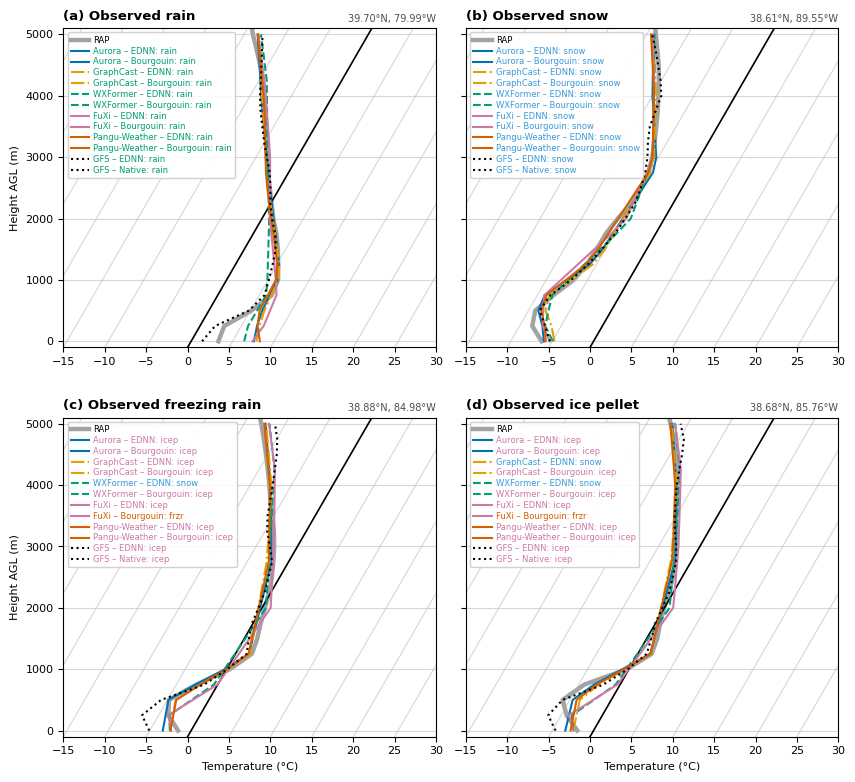

In [9]:
CLASS_COLORS = {"rain": "#009E73", "snow": "#3a9ad9", "icep": "#CC79A7",
                "frzr": "#D55E00", "none": "0.5", "–": "0.5"}
SECOND = {m: ("Native" if m == "GFS" else "Bourgouin") for m in MODELS}
SHORT = {"EDNN": "EDNN", "Bourgouin": "Bourgouin", "Native": "Native"}

def diag_abbr(model, method, r):
    v = diag[(model, method)][r]
    return ABBR.get(v, "–") if np.isfinite(v) else "–"

fig, axs = skew_axes_grid(figsize=(10, 9.2))
for k, (ax, cls) in enumerate(zip(axs, PANEL_CLASSES)):
    r = chosen[cls]
    ax.set_title(f"({'abcd'[k]}) Observed {cls.lower()}", loc="left", fontweight="bold")
    if r is None:
        ax.text(0.5, 0.5, "no report", transform=ax.transAxes, ha="center")
        continue
    rap, = ax.plot(RAP_T[r], RAP_H, **RAP_STYLE)
    lines = {}
    for model in MODELS:
        lines[model], = ax.plot(prof[model][r], heights[model], color=MODEL_COLORS[model],
                                ls=MODEL_LS[model], lw=1.5, zorder=3)
    ax.text(1.0, 1.015, f"{obs.lat[r]:.2f}°N, {abs(obs.lon[r]):.2f}°W",
            transform=ax.transAxes, ha="right", va="bottom", fontsize=7, color="0.3")

    # Internal legend with all 12 systems, grouped by model:
    # each profile line appears twice (EDNN, then Bourgouin / native), since both
    # algorithms diagnose ptype from the same profile.
    handles, labels = [rap], ["RAP"]
    for m in MODELS:
        for method in ("EDNN", SECOND[m]):
            handles.append(lines[m])
            labels.append(f"{m} – {SHORT[method]}: {diag_abbr(m, method, r)}")
    leg = ax.legend(handles, labels, loc="best", ncol=1, fontsize=6,
                    frameon=True, framealpha=0.9, edgecolor="0.8",
                    handlelength=2.2, handletextpad=0.5, borderpad=0.4, labelspacing=0.22)
    for txt in leg.get_texts():
        code = txt.get_text().rsplit(": ", 1)[-1]
        if code in CLASS_COLORS:
            txt.set_color(CLASS_COLORS[code])

fig.savefig(FIG / f"case_study_profiles_{TAG}.pdf", bbox_inches="tight")
fig.savefig(FIG / f"case_study_profiles_{TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
MODELS   = ['WXFormer']

WXFormer       day 1: wxformer_2022-02-03T00Z_018.nc
WXFormer       day 3: wxformer_2022-02-01T00Z_066.nc
WXFormer       day 7: wxformer_2022-01-28T00Z_162.nc


EDNN Bourgouin/Native  T_sfc  warm_max  warm_max_z  cold_depth
model    obs_class     day                                                                
WXFormer Freezing Rain 1    snow             icep  -2.57      0.49      2000.0      1500.0
                       3    snow             snow  -3.64      0.02      2000.0      2000.0
                       7    snow             snow  -3.59     -3.59         0.0      5000.0
         Ice Pellet    1    snow             icep  -2.45      0.62      2000.0      1500.0
                       3    snow             snow  -3.84      0.06      2000.0      2000.0
                       7    snow             snow  -3.32     -3.32         0.0      5000.0
         Rain          1    rain             rain   6.41      6.41         0.0         0.0
                       3    rain             rain   6.24      6.24         0.0         0.0
                       7    rain             rain   9.84      9.84         0.0         0.0
         Snow          1    snow             snow  -4.91     -4.07      2000.0      5000.0
                       3    snow             snow  -6.01     -5.62      2000.0      5000.0
                       7    snow             snow  -8.35     -8.35         0.0      5000.0

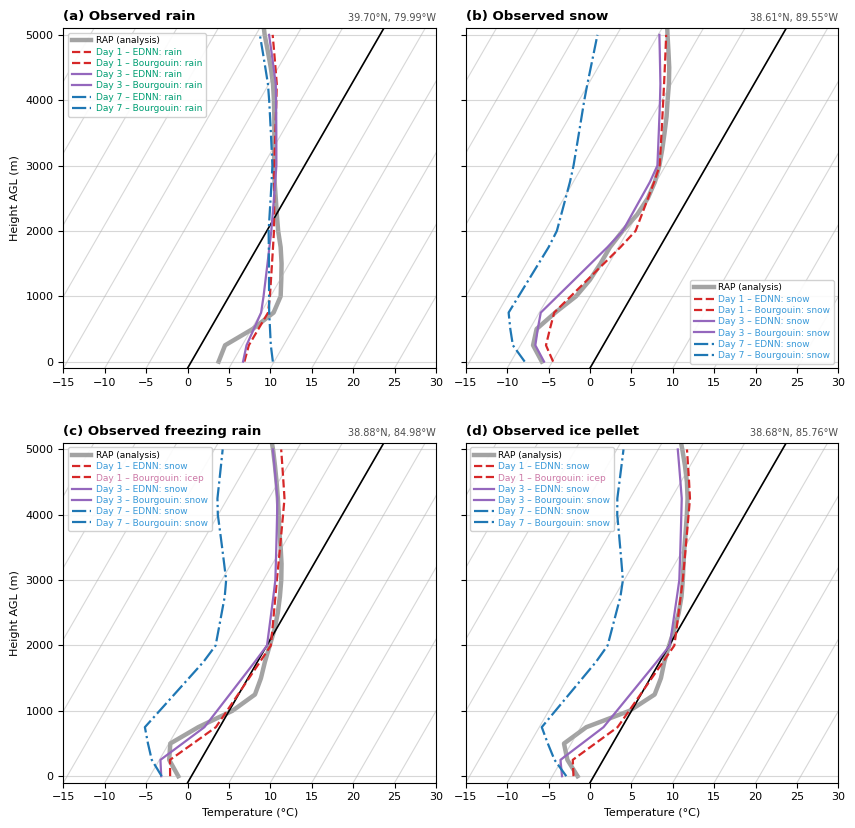

In [11]:
# ==================================================================
# Lead-time dependence: profiles at days 1, 3 and 7 at the same reports
# (one 2 x 2 figure per model; uses chosen, obs, RAP_T, RAP_H and the
#  helpers defined earlier in notebook 07)
# ==================================================================
LT_DAYS = [1, 3, 7]
LT_MODELS = MODELS                      # e.g. ["WXFormer"] for a single figure
LT_TITLE = True                         # model name above each figure (set False for the manuscript version)
LT_STYLE = {1: dict(color="#d62728", ls="--"),
            3: dict(color="#9467bd", ls="-"),
            7: dict(color="#1f77b4", ls="-.")}
CLASS_COLORS = {"rain": "#009E73", "snow": "#3a9ad9", "icep": "#CC79A7",
                "frzr": "#D55E00", "none": "0.5", "–": "0.5"}
SECOND = {m: ("Native" if m == "GFS" else "Bourgouin") for m in MODELS}

sel = {cls: r for cls, r in chosen.items() if r is not None}
sel_cls = list(sel)
sel_idx = np.array([sel[c] for c in sel_cls])
lat_s, lon_s = obs.lat.to_numpy()[sel_idx], obs.lon.to_numpy()[sel_idx]

lt_prof, lt_h, lt_diag = {}, {}, {}
for model in LT_MODELS:
    for day in LT_DAYS:
        init, lead = init_and_lead(VALID, day)
        f = forecast_file(model, init, lead)
        with xr.open_dataset(f, decode_timedelta=False) as ds:
            s = PointSampler(ds, lat_s, lon_s)
            far = s.dist_km > MAX_POINT_KM
            t, _ = s.values(ds[T_VAR])
            lt_h[(model, day)] = heights_of(ds, T_VAR)
            lt_prof[(model, day)] = np.where(far[:, None], np.nan, to_celsius(t))
            for m in ("EDNN", SECOND[model]):
                v, _ = s.values(ds[pick_var(ds, m)])
                lt_diag[(model, day, m)] = np.where(far, np.nan, v.ravel())
        print(f"{model:14s} day {day}: {f.name}")

def lt_abbr(model, day, method, j):
    v = lt_diag[(model, day, method)][j]
    return ABBR.get(v, "–") if np.isfinite(v) else "–"

# diagnostics: surface T, warm-layer peak, cold-layer depth for every model / day / report
rows = []
for model in LT_MODELS:
    for day in LT_DAYS:
        for j, cls in enumerate(sel_cls):
            rows.append({"model": model, "day": day, "obs_class": cls,
                         "EDNN": lt_abbr(model, day, "EDNN", j),
                         "Bourgouin/Native": lt_abbr(model, day, SECOND[model], j),
                         **describe(lt_h[(model, day)], lt_prof[(model, day)][j])})
lt_diag_df = pd.DataFrame(rows).set_index(["model", "obs_class", "day"]).sort_index()
lt_diag_df.to_csv(OUT / f"case_study_profiles_leadtime_diagnostics_{VALID:%Y%m%d_%H}z.csv")
display(lt_diag_df.round(2))

# one figure per model
for model in LT_MODELS:
    fig, axs = skew_axes_grid(figsize=(10, 9.2))
    for k, (ax, cls) in enumerate(zip(axs, PANEL_CLASSES)):
        ax.set_title(f"({'abcd'[k]}) Observed {cls.lower()}", loc="left", fontweight="bold")
        if cls not in sel:
            ax.text(0.5, 0.5, "no report", transform=ax.transAxes, ha="center")
            continue
        j, r = sel_cls.index(cls), sel[cls]
        rap, = ax.plot(RAP_T[r], RAP_H, **RAP_STYLE)
        handles, labels = [rap], ["RAP (analysis)"]
        for day in LT_DAYS:
            ln, = ax.plot(lt_prof[(model, day)][j], lt_h[(model, day)], lw=1.6, zorder=3, **LT_STYLE[day])
            for method in ("EDNN", SECOND[model]):
                handles.append(ln)
                labels.append(f"Day {day} – {method}: {lt_abbr(model, day, method, j)}")
        leg = ax.legend(handles, labels, loc="best", fontsize=6.5, frameon=True, framealpha=0.9,
                        edgecolor="0.8", handlelength=2.2, handletextpad=0.5,
                        borderpad=0.4, labelspacing=0.25)
        for txt in leg.get_texts():
            code = txt.get_text().rsplit(": ", 1)[-1]
            if code in CLASS_COLORS:
                txt.set_color(CLASS_COLORS[code])
        ax.text(1.0, 1.015, f"{obs.lat[r]:.2f}°N, {abs(obs.lon[r]):.2f}°W",
                transform=ax.transAxes, ha="right", va="bottom", fontsize=7, color="0.3")
    if LT_TITLE:
        fig.subplots_adjust(top=0.93)
    #     fig.suptitle(f"{model}: forecasts valid {VALID:%H%M} UTC {VALID:%-d %B %Y}",
    #                  fontweight="bold", fontsize=9, y=0.975)
    slug = model.lower().replace("-", "")
    fig.savefig(FIG / f"case_study_profiles_leadtime_{slug}_{VALID:%Y%m%d_%H}z.pdf", bbox_inches="tight")
    #fig.savefig(FIG / f"case_study_profiles_leadtime_{slug}_{VALID:%Y%m%d_%H}z.png", dpi=200, bbox_inches="tight")
    plt.show()